/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator LabelEncoder from version 1.9.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input

Class weights: {0: np.float64(0.7048458149779736), 1: np.float64(0.5653710247349824), 2: np.float64(0.7655502392344498), 3: np.float64(2.2535211267605635), 4: np.float64(16.0)}
Epoch 1/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.2812 - loss: 1.6319 - val_accuracy: 0.4000 - val_loss: 1.5648
Epoch 2/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3656 - loss: 1.5032 - val_accuracy: 0.3438 - val_loss: 1.5361
Epoch 3/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4156 - loss: 1.2201 - val_accuracy: 0.4000 - val_loss: 1.4732
Epoch 4/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4484 - loss: 1.2031 - val_accuracy: 0.4375 - val_loss: 1.4241
Epoch 5/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4516 - loss: 1.0319 - val_accuracy: 0.4812 - val_loss: 1.3406
Epoch 6/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4984 - loss: 1.0043 - val_accuracy: 0.5125 - val_loss: 1.2438
Epoch 7/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accurac

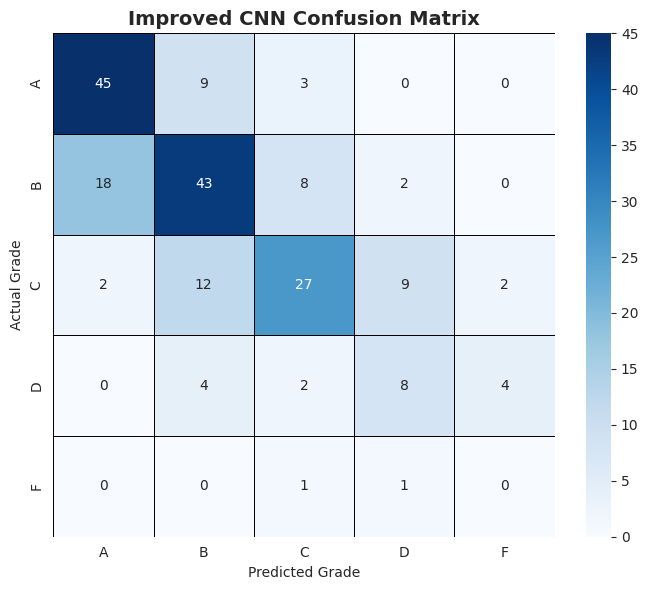

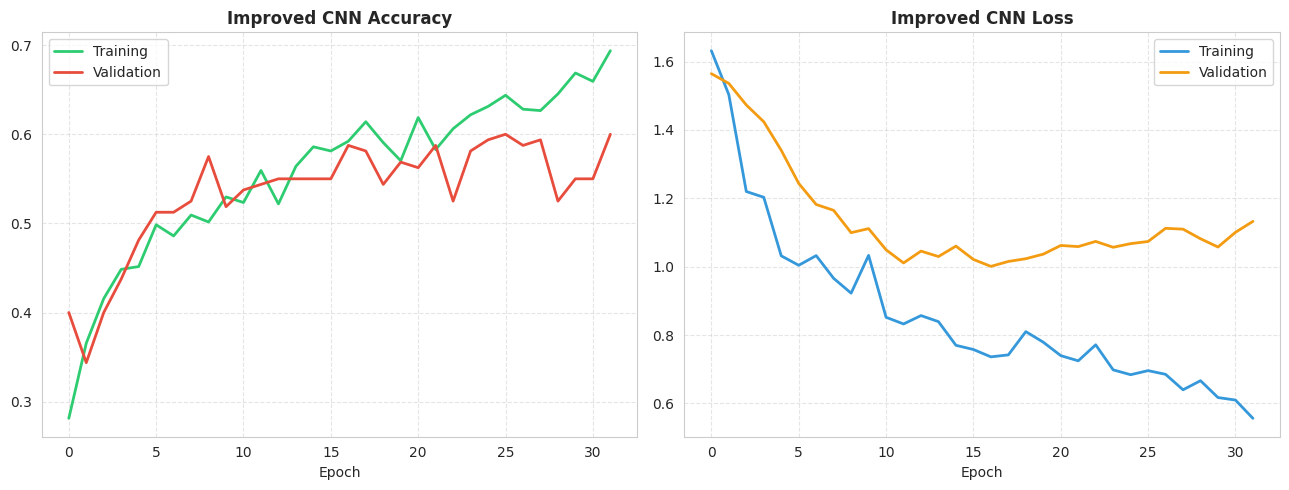


Saved cnn_model_improved.h5


FileNotFoundError: [Errno 2] No such file or directory: 'Model_Comparison_Improved.csv'

In [1]:
# ==========================================================
# TRAIN CNN (IMPROVED) — class-weighted, early-stopped,
# slightly deeper architecture. Uses the SAME preprocessing,
# split and scaler as the other models for a fair comparison.
#
# BEFORE RUNNING: upload these 5 files into this Colab session
# (left sidebar -> Files -> upload):
#   student_performance_dataset.csv
#   scaler.pkl
#   label_encoders.pkl
#   meta.pkl
#   Model_Comparison_Improved.csv
# ==========================================================

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

sns.set_style("whitegrid")

# ------------------------------------------------------------
# 1. Load the SAME scaler / encoders / column info as the
#    other models (Random Forest, KNN, SVM, XGBoost, Ensemble)
# ------------------------------------------------------------
scaler = joblib.load("scaler.pkl")
label_encoders = joblib.load("label_encoders.pkl")
meta = joblib.load("meta.pkl")

feature_columns = meta["feature_columns"]
class_names = np.array(meta["class_names"])

# ------------------------------------------------------------
# 2. Rebuild X, y EXACTLY the same way
# ------------------------------------------------------------
df = pd.read_csv("student_performance_dataset.csv")
df["parental_education"] = df["parental_education"].fillna("High School")

cat_cols = ["gender", "parental_education", "internet_access",
            "extracurricular_activities", "part_time_job", "final_grade"]
for col in cat_cols:
    df[col] = label_encoders[col].transform(df[col])

X = df.drop(["student_id", "final_grade"], axis=1)[feature_columns]
y = df["final_grade"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

X_train_cnn = X_train_s.reshape(X_train_s.shape[0], X_train_s.shape[1], 1)
X_test_cnn = X_test_s.reshape(X_test_s.shape[0], X_test_s.shape[1], 1)

# ------------------------------------------------------------
# 3. Class weights — the F grade is only ~1% of the data,
#    so without this the CNN mostly ignores it
# ------------------------------------------------------------
class_weights_arr = compute_class_weight(
    class_weight="balanced", classes=np.unique(y_train), y=y_train
)
class_weight_dict = dict(enumerate(class_weights_arr))
print("Class weights:", class_weight_dict)

# ------------------------------------------------------------
# 4. Build a slightly deeper CNN with dropout + batch norm,
#    and stop automatically once validation loss stops improving
# ------------------------------------------------------------
model = Sequential([
    Conv1D(filters=64, kernel_size=2, activation="relu",
           input_shape=(X_train_s.shape[1], 1)),
    BatchNormalization(),
    Conv1D(filters=32, kernel_size=2, activation="relu"),
    Flatten(),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dense(len(class_names), activation="softmax"),
])

model.compile(optimizer=Adam(learning_rate=0.001),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

early_stop = EarlyStopping(
    monitor="val_loss", patience=15, restore_best_weights=True
)

history = model.fit(
    X_train_cnn, y_train,
    validation_split=0.2,
    epochs=150,
    batch_size=16,
    class_weight=class_weight_dict,
    callbacks=[early_stop],
    verbose=1,
)

# ------------------------------------------------------------
# 5. Evaluate
# ------------------------------------------------------------
loss, cnn_accuracy = model.evaluate(X_test_cnn, y_test, verbose=0)
cnn_prob = model.predict(X_test_cnn)
cnn_pred = np.argmax(cnn_prob, axis=1)

cnn_precision = precision_score(y_test, cnn_pred, average="weighted", zero_division=0)
cnn_recall = recall_score(y_test, cnn_pred, average="weighted", zero_division=0)
cnn_f1 = f1_score(y_test, cnn_pred, average="weighted", zero_division=0)

print("=" * 60)
print("IMPROVED CNN RESULTS")
print("=" * 60)
print(f"Accuracy  : {cnn_accuracy:.4f}")
print(f"Precision : {cnn_precision:.4f}")
print(f"Recall    : {cnn_recall:.4f}")
print(f"F1 Score  : {cnn_f1:.4f}")
print(f"Stopped after {len(history.history['loss'])} epochs (early stopping)")
print()
print(classification_report(y_test, cnn_pred, target_names=class_names, zero_division=0))

# ------------------------------------------------------------
# 6. Confusion matrix
# ------------------------------------------------------------
cm = confusion_matrix(y_test, cnn_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names,
            linewidths=0.5, linecolor="black")
plt.title("Improved CNN Confusion Matrix", fontsize=14, fontweight="bold")
plt.xlabel("Predicted Grade"); plt.ylabel("Actual Grade")
plt.tight_layout()
plt.savefig("CNN_Confusion_Matrix_Improved.png", dpi=300, facecolor="white")
plt.show()

# ------------------------------------------------------------
# 7. Training curves
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(history.history["accuracy"], label="Training", linewidth=2, color="#2ecc71")
axes[0].plot(history.history["val_accuracy"], label="Validation", linewidth=2, color="#e74c3c")
axes[0].set_title("Improved CNN Accuracy", fontweight="bold")
axes[0].set_xlabel("Epoch"); axes[0].legend(); axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].plot(history.history["loss"], label="Training", linewidth=2, color="#3498db")
axes[1].plot(history.history["val_loss"], label="Validation", linewidth=2, color="#f39c12")
axes[1].set_title("Improved CNN Loss", fontweight="bold")
axes[1].set_xlabel("Epoch"); axes[1].legend(); axes[1].grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("CNN_Training_Curves_Improved.png", dpi=300, facecolor="white")
plt.show()

# ------------------------------------------------------------
# 8. Save model + update the comparison table
# ------------------------------------------------------------
model.save("cnn_model_improved.h5")
print("\nSaved cnn_model_improved.h5")

comp = pd.read_csv("Model_Comparison_Improved.csv")
comp = comp[comp["Model"] != "CNN"]
comp = pd.concat([comp, pd.DataFrame([{
    "Model": "CNN", "Accuracy": cnn_accuracy, "Precision": cnn_precision,
    "Recall": cnn_recall, "F1 Score": cnn_f1,
}])], ignore_index=True).sort_values("Accuracy", ascending=False)
comp.to_csv("Model_Comparison_Improved.csv", index=False)
print("\nFinal comparison, all 5 models:\n", comp)

print("\nDONE. Download these files:")
print(" - cnn_model_improved.h5")
print(" - Model_Comparison_Improved.csv   (now has all 5 models)")
print(" - CNN_Confusion_Matrix_Improved.png")
print(" - CNN_Training_Curves_Improved.png")


In [2]:
import pandas as pd

# Load the file you actually uploaded (3 rows: SVM, KNN, Random Forest)
comp = pd.read_csv("Model_Comparison.csv")

# Add the CNN row using the results already sitting in memory from the run above
comp = comp[comp["Model"] != "CNN"]
comp = pd.concat([comp, pd.DataFrame([{
    "Model": "CNN",
    "Accuracy": cnn_accuracy,
    "Precision": cnn_precision,
    "Recall": cnn_recall,
    "F1 Score": cnn_f1,
}])], ignore_index=True).sort_values("Accuracy", ascending=False)

comp.to_csv("Model_Comparison.csv", index=False)
print(comp)

           Model  Accuracy  Precision  Recall  F1 Score
3            CNN     0.615   0.629012   0.615  0.618749
0            SVM     0.590   0.609646   0.590  0.593743
1            KNN     0.565   0.594629   0.565  0.546386
2  Random Forest     0.540   0.555074   0.540  0.544984
